# Part 4: Overfitting and Regularization

Run top to bottom. `FAST=0` runs at full scale (see README).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import mlcore as mc

FAST = mc.fast_mode()  # R2: FAST=0 for full scale
rng = np.random.default_rng(mc.SEED)  # R2 seed; experiments use mc.rng_for(tag)
print(f"FAST={FAST}")

FAST=True


## 4.1 ⋆ The anatomy of overfitting

Inputs $x \sim U[-1,1]$; target $f(x)=\sum_{q=0}^{Q_f} a_q L_q(x)$ with $a_q\sim N(0,1)$ rescaled so that $E_x[f^2]=\sum_q a_q^2/(2q+1)=1$; data $y_n=f(x_n)+\sigma\epsilon_n$.
We fit $g_2\in\mathcal H_2$ and $g_{10}\in\mathcal H_{10}$ by least squares on Legendre features and report the overfit measure $E_{out}(g_{10})-E_{out}(g_2)$.

**4.1(d) analytic $E_{out}$.** For $g=\sum_q b_q L_q$ (coefficients zero-padded to a common length), orthogonality $E[L_pL_q]=\delta_{pq}/(2q+1)$ gives
$$E_{out}(g)=\sum_q \frac{(b_q-a_q)^2}{2q+1}+\sigma^2 ,$$
so $\sigma^2$ cancels in the overfit measure. Derivation: report, Section II. Runs are batched (`mc.overfit_measure`), 500 per cell.

In [2]:
from matplotlib.colors import Normalize

RUNS = 500
N_grid = np.arange(20, 131, 5)
s2_grid = np.round(np.arange(0, 2.01, 0.1), 1)
Qf_grid = np.arange(1, 51)

rng_a = mc.rng_for("4_1a")
om_a, se_a, md_a = (np.zeros((N_grid.size, s2_grid.size)) for _ in range(3))
for i, N in enumerate(N_grid):
    for j, s2 in enumerate(s2_grid):
        runs = mc.overfit_measure(rng_a, N, s2, 20, RUNS)
        om_a[i, j], se_a[i, j] = mc.mean_se(runs)
        md_a[i, j] = np.median(runs)

rng_b = mc.rng_for("4_1b")
om_b, se_b, md_b = (np.zeros((N_grid.size, Qf_grid.size)) for _ in range(3))
for i, N in enumerate(N_grid):
    for j, Qf in enumerate(Qf_grid):
        runs = mc.overfit_measure(rng_b, N, 0.1, Qf, RUNS)
        om_b[i, j], se_b[i, j] = mc.mean_se(runs)
        md_b[i, j] = np.median(runs)

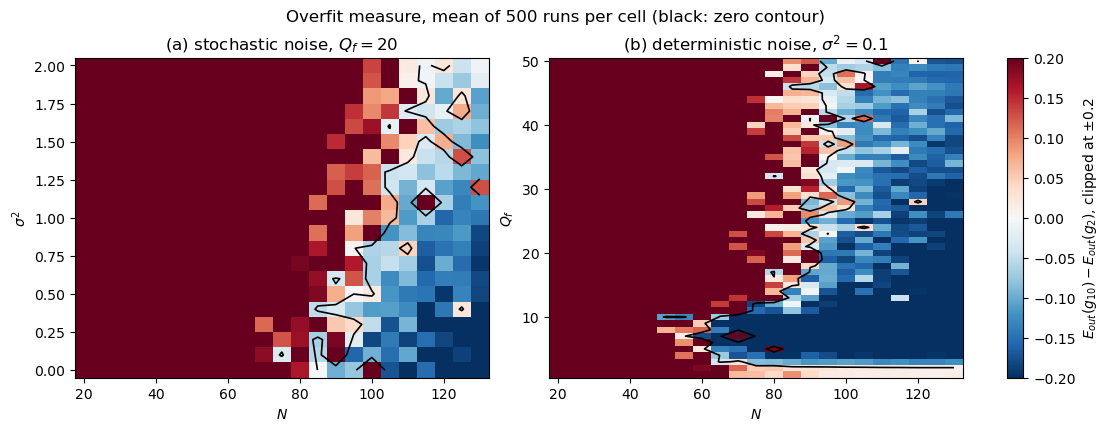

In [3]:
CLIP = 0.2
norm = Normalize(vmin=-CLIP, vmax=CLIP, clip=True)


def heatmap(ax, om, grid, ylabel, title):
    mesh = ax.pcolormesh(N_grid, grid, om.T, cmap="RdBu_r", norm=norm, shading="nearest", rasterized=True)
    ax.contour(N_grid, grid, om.T, levels=[0], colors="k", linewidths=1.2)
    ax.set(xlabel="$N$", ylabel=ylabel, title=title)
    return mesh


fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
heatmap(axes[0], om_a, s2_grid, r"$\sigma^2$", r"(a) stochastic noise, $Q_f = 20$")
mesh = heatmap(axes[1], om_b, Qf_grid, r"$Q_f$", r"(b) deterministic noise, $\sigma^2 = 0.1$")
fig.colorbar(mesh, ax=axes, label=rf"$E_{{out}}(g_{{10}}) - E_{{out}}(g_2)$, clipped at $\pm{CLIP}$")
fig.suptitle(f"Overfit measure, mean of {RUNS} runs per cell (black: zero contour)")
mc.savefig(fig, "4_1c_heatmaps")
plt.show()

**Interpretation.** Both heatmaps show overfitting at small $N$, with the zero contour moving to larger $N$ as either kind of noise grows, as in LFD Fig. 4.3. The mean is heavy-tailed: at $N=20$ the median overfit measure is 4 to 70, but rare runs with $N$ close to 11 parameters oscillate wildly, so 75% of the cells in (a) have a positive mean and only 41% a positive median.

In [4]:
def first_negative_N(col):
    neg = np.flatnonzero(col < 0)
    return int(N_grid[neg[0]]) if neg.size else None


print(f"cells with mean > 0: (a) {np.mean(om_a > 0):.0%}, (b) {np.mean(om_b > 0):.0%}; median > 0: (a) {np.mean(md_a > 0):.0%}, (b) {np.mean(md_b > 0):.0%}")
for label, om, se, md, grid, vals in (("sigma^2", om_a, se_a, md_a, s2_grid, (0.0, 0.5, 1.0, 2.0)),
                                      ("Qf", om_b, se_b, md_b, Qf_grid, (2, 10, 20, 50))):
    for v in vals:
        j = int(np.flatnonzero(np.isclose(grid, v))[0])
        print(f"{label} = {v}: N=20 median {md[0, j]:.3g} | N=130 mean {om[-1, j]:.3f} ± {se[-1, j]:.3f}"
              f" | first N with median < 0: {first_negative_N(md[:, j])}, mean < 0: {first_negative_N(om[:, j])}")

cells with mean > 0: (a) 75%, (b) 62%; median > 0: (a) 41%, (b) 24%
sigma^2 = 0.0: N=20 median 11.4 | N=130 mean -0.223 ± 0.036 | first N with median < 0: 40, mean < 0: 85
sigma^2 = 0.5: N=20 median 31.3 | N=130 mean -0.184 ± 0.022 | first N with median < 0: 55, mean < 0: 105
sigma^2 = 1.0: N=20 median 56.1 | N=130 mean -0.144 ± 0.029 | first N with median < 0: 65, mean < 0: 110
sigma^2 = 2.0: N=20 median 69.7 | N=130 mean -0.008 ± 0.077 | first N with median < 0: 95, mean < 0: 115
Qf = 2: N=20 median 6.17 | N=130 mean 0.010 ± 0.001 | first N with median < 0: None, mean < 0: None
Qf = 10: N=20 median 4.4 | N=130 mean -0.402 ± 0.011 | first N with median < 0: 30, mean < 0: 50
Qf = 20: N=20 median 14.1 | N=130 mean -0.240 ± 0.014 | first N with median < 0: 40, mean < 0: 95
Qf = 50: N=20 median 15.4 | N=130 mean -0.175 ± 0.010 | first N with median < 0: 55, mean < 0: 95


**Interpretation.** With stochastic noise, the first $N$ with a negative median moves from 40 ($\sigma^2=0$) to 95 ($\sigma^2=2$). Deterministic noise does the same, from 30 ($Q_f=10$) to 40 ($Q_f=20$) and 55 ($Q_f=50$), because the orders above 10 that $\mathcal H_{10}$ cannot represent act like noise. When $\sigma^2$ is small, $\mathcal H_{10}$ fits that high-order part: on 20 to 50 points, $L_{11},\dots,L_{Q_f}$ are not orthogonal to the low orders, so least squares aliases them into wrong coefficients. For $Q_f=2$ the target lies inside $\mathcal H_2$, and $\mathcal H_{10}$ overfits at every $N$ ($+0.010\pm0.001$ at $N=130$).

## 4.2 Weight decay (L2)

$w_{reg}=(Z^TZ+\lambda I)^{-1}Z^Ty$ minimizes $E_{aug}(w)=E_{in}(w)+\frac{\lambda}{N}w^Tw$ (brief 4.2 form). The bias $w_0$ is not penalized unless stated (DECISIONS row 8; 4.2(e) justifies it).
Setup: Legendre target $Q_f=15$, $N=30$, fit $\mathcal H_{10}$, $\sigma^2=0.5$ for the base case (DECISIONS row 10).
`mc.ridge_svd` computes $w_{reg}$, $d_{eff}$ and the hat diagonal for the whole $\lambda$ grid from one SVD per dataset; $E_{out}$ is analytic, as in 4.1.

In [5]:
LAMS = np.r_[0.0, np.logspace(-4, 2, 61)]
RUNS_42 = 500


def ridge_sweep(tag, N, sigma2, Qf, runs=RUNS_42, lams=LAMS, penalize_bias=False, shift=0.0):
    # per-run Ein and Eout over the lambda grid
    # same tag -> same datasets
    rng = mc.rng_for(tag)
    ein, eout = np.empty((runs, lams.size)), np.empty((runs, lams.size))
    for r in range(runs):
        x, y, a = mc.legendre_dataset(rng, N, sigma2, Qf)
        if shift:
            y, a = y + shift, a.copy()
            a[0] += shift
        Z = mc.legendre_features(x, 10)
        W = mc.ridge_svd(Z, y, lams, penalize_bias)["W"]
        ein[r] = np.mean((Z @ W.T - y[:, None]) ** 2, axis=0)
        eout[r] = mc.eout_legendre(W, a, sigma2)
    return ein, eout

In [6]:
CASES = [(0.0, 15), (0.25, 15), (0.5, 15), (1.0, 15), (0.0, 30)]
sweeps = {}
print(f"{'case':<20}{'lambda*':>10}{'Eout(lambda*)':>20}{'Eout(lambda=0) mean':>26}{'median':>9}{'Eout(1e-4) median':>19}")
for s2, Qf in CASES:
    ein, eout = ridge_sweep(f"4_2_{s2}_{Qf}", 30, s2, Qf)
    m, se = mc.mean_se(eout)
    med = np.median(eout, axis=0)
    k = int(np.argmin(m))
    sweeps[(s2, Qf)] = {"ein": mc.mean_se(ein), "eout": (m, se), "eout_med": med, "k": k}
    print(f"sigma^2={s2:<4} Qf={Qf:<4}{LAMS[k]:>10.3g}{m[k]:>12.4f} ± {se[k]:.4f}{m[0]:>16.4g} ± {se[0]:<8.3g}{med[0]:>9.3f}{med[1]:>19.3f}")
print(f"{RUNS_42} runs per case; lambda grid = {{0}} and 61 log-spaced values in [1e-4, 1e2]")
BASE = (0.5, 15)
lam_star = LAMS[sweeps[BASE]["k"]]

case                   lambda*       Eout(lambda*)       Eout(lambda=0) mean   median  Eout(1e-4) median
sigma^2=0.0  Qf=15       0.501      0.2342 ± 0.0079            3398 ± 2.78e+03    0.728              0.698
sigma^2=0.25 Qf=15           1      0.5510 ± 0.0077            1103 ± 719         1.463              1.437


sigma^2=0.5  Qf=15        1.26      0.8480 ± 0.0077       1.482e+04 ± 1.44e+04    3.140              3.111
sigma^2=1.0  Qf=15        2.51      1.4263 ± 0.0090            5116 ± 2.9e+03     3.327              3.250
sigma^2=0.0  Qf=30       0.794      0.3815 ± 0.0087            2776 ± 2.28e+03    1.007              0.990
500 runs per case; lambda grid = {0} and 61 log-spaced values in [1e-4, 1e2]


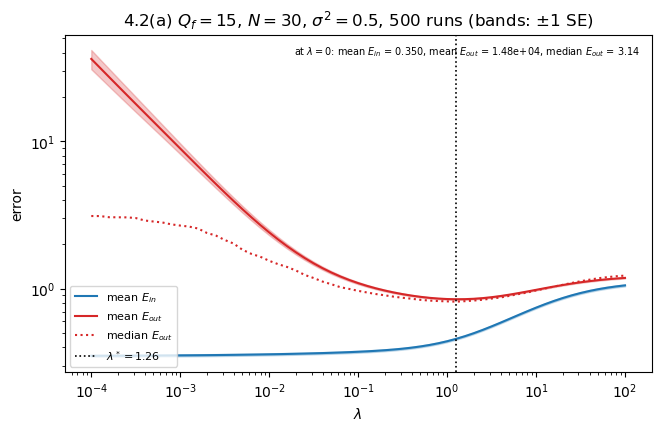

In [7]:
def mark_lambda(ax, k, color="k", label=None):
    if k == 0:
        ax.text(0.02, 0.95, r"$\lambda^* = 0$", transform=ax.transAxes, va="top")
    else:
        ax.axvline(LAMS[k], color=color, ls=":", lw=1.2, label=label)


s = sweeps[BASE]
lp = LAMS[1:]
fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
for key, color, name in (("ein", "C0", "E_{in}"), ("eout", "C3", "E_{out}")):
    m, se = s[key]
    ax.plot(lp, m[1:], color=color, label=f"mean ${name}$")
    ax.fill_between(lp, np.maximum(m[1:] - se[1:], 1e-3), m[1:] + se[1:], color=color, alpha=0.25)
ax.plot(lp, s["eout_med"][1:], color="C3", ls=":", label="median $E_{out}$")
mark_lambda(ax, s["k"], label=rf"$\lambda^* = {lam_star:.3g}$")
m_in, m_out = s["ein"][0][0], s["eout"][0][0]
ax.text(0.98, 0.97, rf"at $\lambda = 0$: mean $E_{{in}}$ = {m_in:.3f}, mean $E_{{out}}$ = {m_out:.3g}, median $E_{{out}}$ = {s['eout_med'][0]:.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=7)
ax.set(xscale="log", yscale="log", xlabel=r"$\lambda$", ylabel="error",
       title=rf"4.2(a) $Q_f = 15$, $N = 30$, $\sigma^2 = 0.5$, {RUNS_42} runs (bands: ±1 SE)")
ax.legend(fontsize=8, loc="lower left")
mc.savefig(fig, "4_2a_lambda_sweep")
plt.show()

**Interpretation.** $E_{in}$ rises with $\lambda$ (0.350 at $\lambda=0$), while $E_{out}$ is U-shaped with its minimum $0.848\pm0.008$ at $\lambda^*=1.26$. At $\lambda=0$ the mean $E_{out}$ is $1.5\times10^4$ (median 3.14), the heavy tail of 4.1, and a small $\lambda$ removes it by damping the near-singular directions.

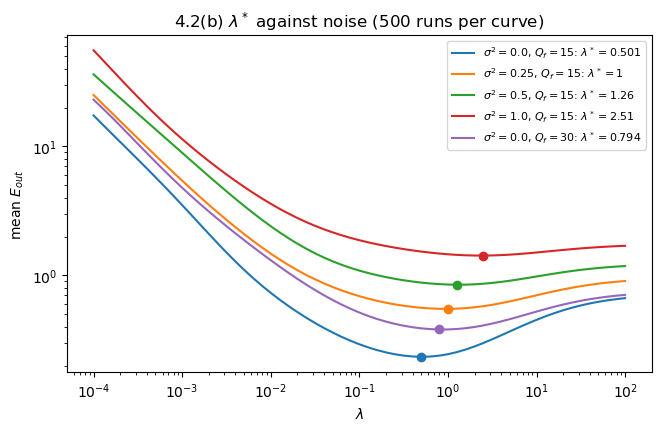

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
for c, (s2, Qf) in enumerate(CASES):
    m, se = sweeps[(s2, Qf)]["eout"]
    k = sweeps[(s2, Qf)]["k"]
    label = rf"$\sigma^2 = {s2}$, $Q_f = {Qf}$: $\lambda^* = {LAMS[k]:.3g}$"
    ax.plot(lp, m[1:], color=f"C{c}", label=label)
    ax.plot(max(LAMS[k], lp[0]), m[k], "o", color=f"C{c}")
ax.set(xscale="log", yscale="log", xlabel=r"$\lambda$", ylabel=r"mean $E_{out}$",
       title=rf"4.2(b) $\lambda^*$ against noise ({RUNS_42} runs per curve)")
ax.legend(fontsize=8)
mc.savefig(fig, "4_2b_noise_lambda_star")
plt.show()

**Interpretation.** $\lambda^*$ grows with stochastic noise: 0.50, 1.0, 1.26 and 2.51 for $\sigma^2=0$, 0.25, 0.5 and 1. With no stochastic noise it is still positive (0.50 for $Q_f=15$, 0.79 for $Q_f=30$) because of deterministic noise.

d_eff(0) = 11.000000 (unpenalized bias), 11.000000 (penalized bias)
d_eff(1e12) = 1.000000 (unpenalized bias), 7.14e-11 (penalized bias)
d_eff at lambda* = 1.26: 7.30 (unpenalized bias)


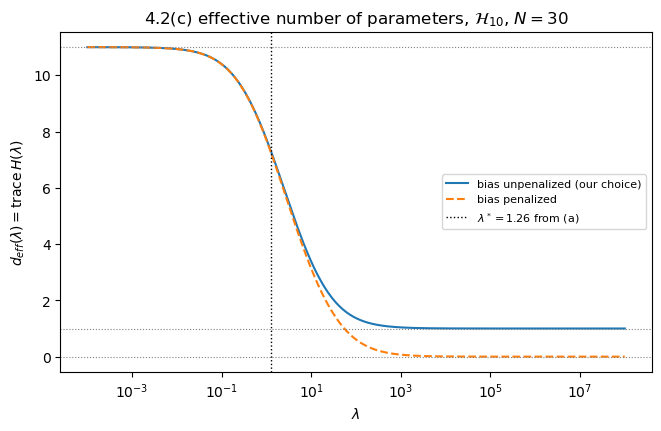

In [9]:
x, y, a = mc.legendre_dataset(mc.rng_for("4_2c"), 30, 0.5, 15)
Z = mc.legendre_features(x, 10)
lam_c = np.logspace(-4, 8, 300)
d_unpen = mc.ridge_svd(Z, y, lam_c)["d_eff"]
d_pen = mc.ridge_svd(Z, y, lam_c, penalize_bias=True)["d_eff"]
lim_u = mc.ridge_svd(Z, y, [0.0, 1e12])["d_eff"]
lim_p = mc.ridge_svd(Z, y, [0.0, 1e12], penalize_bias=True)["d_eff"]
print(f"d_eff(0) = {lim_u[0]:.6f} (unpenalized bias), {lim_p[0]:.6f} (penalized bias)")
print(f"d_eff(1e12) = {lim_u[1]:.6f} (unpenalized bias), {lim_p[1]:.2e} (penalized bias)")
assert abs(lim_u[0] - 11) < 1e-6 and abs(lim_p[0] - 11) < 1e-6
assert abs(lim_u[1] - 1) < 1e-6 and abs(lim_p[1]) < 1e-6
print(f"d_eff at lambda* = {lam_star:.3g}: {mc.ridge_svd(Z, y, lam_star)['d_eff'][0]:.2f} (unpenalized bias)")

fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
ax.plot(lam_c, d_unpen, label="bias unpenalized (our choice)")
ax.plot(lam_c, d_pen, ls="--", label="bias penalized")
for level in (11, 1, 0):
    ax.axhline(level, color="gray", lw=0.8, ls=":")
ax.axvline(lam_star, color="k", ls=":", lw=1, label=rf"$\lambda^* = {lam_star:.3g}$ from (a)")
ax.set(xscale="log", xlabel=r"$\lambda$", ylabel=r"$d_{eff}(\lambda) = \mathrm{trace}\,H(\lambda)$",
       title=r"4.2(c) effective number of parameters, $\mathcal{H}_{10}$, $N = 30$")
ax.legend(fontsize=8)
mc.savefig(fig, "4_2c_deff")
plt.show()

**Interpretation.** $d_{eff}$ falls from 11 at $\lambda=0$ to 1 with an unpenalized bias, where the model becomes the constant $\bar y$, and to 0 with a penalized bias. At $\lambda^*=1.26$ it is 7.30, since each direction counts $s_i^2/(s_i^2+\lambda)$.

under-regularized  lambda = 0        Eout = 8710.440
well-regularized   lambda = 1.26     Eout = 0.771
over-regularized   lambda = 100      Eout = 1.063


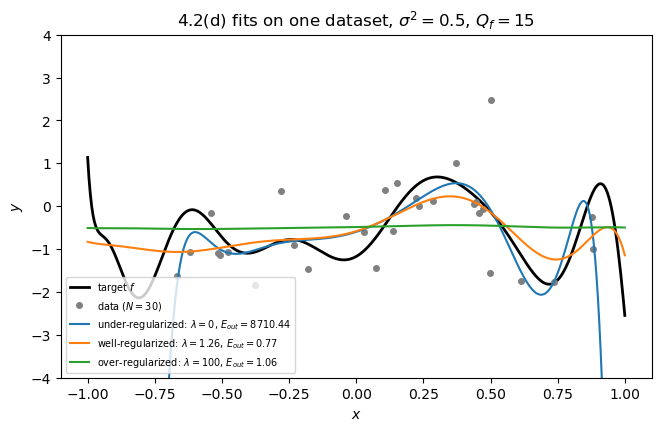

In [10]:
x, y, a = mc.legendre_dataset(mc.rng_for("4_2d"), 30, 0.5, 15)
Z = mc.legendre_features(x, 10)
lam_d = [0.0, lam_star, 100.0]
names = ["under-regularized", "well-regularized", "over-regularized"]
W = mc.ridge_svd(Z, y, lam_d)["W"]
eout_d = mc.eout_legendre(W, a, 0.5)
xg = np.linspace(-1, 1, 400)
fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
ax.plot(xg, mc.legendre_features(xg, 15) @ a, "k", lw=2, label="target $f$")
ax.plot(x, y, "o", color="gray", ms=4, label="data ($N = 30$)")
for c, (lam, name, e) in enumerate(zip(lam_d, names, eout_d)):
    ax.plot(xg, mc.legendre_features(xg, 10) @ W[c], color=f"C{c}",
            label=rf"{name}: $\lambda = {lam:.3g}$, $E_{{out}} = {e:.2f}$")
    print(f"{name:<18} lambda = {lam:<8.3g} Eout = {e:.3f}")
ax.set(xlabel="$x$", ylabel="$y$", ylim=(-4, 4), title=r"4.2(d) fits on one dataset, $\sigma^2 = 0.5$, $Q_f = 15$")
ax.legend(fontsize=7, loc="lower left")
mc.savefig(fig, "4_2d_fits")
plt.show()

**Interpretation.** On one dataset, $\lambda=0$ chases the points ($E_{out}=8710$), $\lambda^*=1.26$ follows $f$ (0.771) and $\lambda=100$ is almost flat (1.063). These are the under-, well- and over-regularized fits.

unpenalized bias           lambda* = 1.26     Eout(lambda*) = 0.8480 ± 0.0077   Eout(lambda=100) = 1.1833 ± 0.0107
penalized bias             lambda* = 1.26     Eout(lambda*) = 0.8448 ± 0.0077   Eout(lambda=100) = 1.3252 ± 0.0042
unpenalized bias, y + 3    lambda* = 1.26     Eout(lambda*) = 0.8480 ± 0.0077   Eout(lambda=100) = 1.1833 ± 0.0107
penalized bias, y + 3      lambda* = 1        Eout(lambda*) = 0.8729 ± 0.0087   Eout(lambda=100) = 6.6626 ± 0.0880


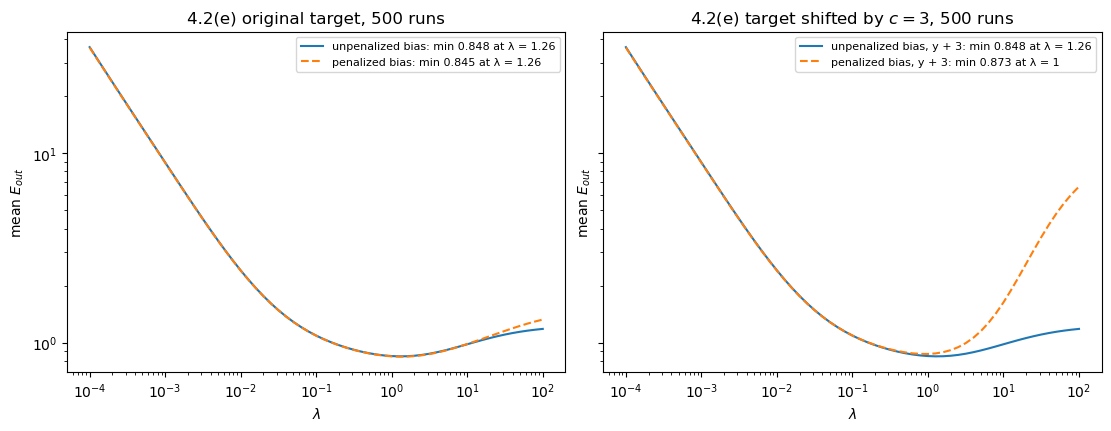

In [11]:
# 4.2(e) bias penalized or not, y shifted by 3
tag = "4_2_0.5_15"
variants = {
    "unpenalized bias": ridge_sweep(tag, 30, 0.5, 15)[1],
    "penalized bias": ridge_sweep(tag, 30, 0.5, 15, penalize_bias=True)[1],
    "unpenalized bias, y + 3": ridge_sweep(tag, 30, 0.5, 15, shift=3.0)[1],
    "penalized bias, y + 3": ridge_sweep(tag, 30, 0.5, 15, penalize_bias=True, shift=3.0)[1],
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True, sharey=True)
for name, eout in variants.items():
    m, se = mc.mean_se(eout)
    k = int(np.argmin(m))
    ax = axes[1] if "y + 3" in name else axes[0]
    ax.plot(lp, m[1:], ls="--" if name.startswith("penalized") else "-", label=f"{name}: min {m[k]:.3f} at λ = {LAMS[k]:.3g}")
    print(f"{name:<26} lambda* = {LAMS[k]:<8.3g} Eout(lambda*) = {m[k]:.4f} ± {se[k]:.4f}   Eout(lambda=100) = {m[-1]:.4f} ± {se[-1]:.4f}")
for ax, t in zip(axes, ("original target", "target shifted by $c = 3$")):
    ax.set(xscale="log", yscale="log", xlabel=r"$\lambda$", ylabel=r"mean $E_{out}$", title=f"4.2(e) {t}, {RUNS_42} runs")
    ax.legend(fontsize=8)
mc.savefig(fig, "4_2e_bias_penalty")
plt.show()

**Interpretation.** We leave the bias unpenalized (DECISIONS row 8). Penalizing it barely matters at $\lambda^*$ (0.845 against 0.848) but hurts at $\lambda=100$ (1.33 against 1.18), and after shifting $y$ by 3 the penalized model degrades to 6.66 while the unpenalized one is unchanged. A method should not depend on the origin of $y$.

## 4.3 ⋆ Sparsity with L1

L1-regularized linear regression, $E_{in}(w)+\lambda\lVert\tilde w\rVert_1$ with $E_{in}=\frac1N\lVert Xw-y\rVert^2$ and the bias unpenalized (brief 4.3 form), solved by proximal gradient (ISTA):
$$w\leftarrow S_{\eta\lambda}\big(w-\eta\nabla E_{in}(w)\big),\qquad S_t(v)=\mathrm{sign}(v)\max(|v|-t,0),\qquad \eta=1/L,\ L=2\lambda_{max}(X^TX)/N .$$
The path runs from $\lambda_{max}$ (all weights zero) down three decades, warm-starting each $\lambda$ at the previous solution (`mc.prox_path`).
Data: `load_diabetes`, degree-2 expansion (10 linear terms, 10 squares, 45 interactions). $\mathrm{sex}^2$ is dropped because sex takes two values, which makes $\mathrm{sex}^2$ an affine function of sex (DECISIONS row 4), leaving 64 features.
All 442 patients, standardized.

In [12]:
from sklearn.datasets import load_breast_cancer, load_diabetes   # data loading only (R1)

diab = load_diabetes()
Xd_raw, yd = diab.data, diab.target
combos_all = mc.poly_feature_combos(10, 2)
drop = combos_all.index((1, 1))  # sex^2
keep = [k for k in range(len(combos_all)) if k != drop]
Pd, combos_d = mc.poly_features(Xd_raw, 2)[:, keep], [combos_all[k] for k in keep]


def term_name(c, names):
    return names[c[0]] if len(c) == 1 else (f"{names[c[0]]}²" if c[0] == c[1] else f"{names[c[0]]}×{names[c[1]]}")


names_d = [term_name(c, diab.feature_names) for c in combos_d]
print(f"sex takes {np.unique(Xd_raw[:, 1]).size} distinct values, so sex² is affine in sex and is dropped: {Pd.shape[1]} features")
Z3, prm3 = mc.standardize(Pd)
X3, y3, N3 = mc.add_bias(Z3), yd, yd.size
print(f"N = {N3}, kappa(Z) = {np.linalg.cond(Z3):.0f}")

lg3 = lambda w: mc.linreg_loss_grad(w, X3, y3)  # noqa: E731
eta3 = 1 / mc.lipschitz_linreg(X3)
lam_max = 2 * np.max(np.abs(Z3.T @ (y3 - y3.mean()))) / N3  # all weights zero above this
LAM1 = lam_max * np.logspace(0, -3, 40)
W1, it1 = mc.prox_path(lg3, X3.shape[1], eta3, LAM1, 100_000, tol=1e-10)
print(f"ISTA iterations per lambda: median {np.median(it1):.0f}, max {it1.max()}")
nnz1 = np.sum(W1[:, 1:] != 0, axis=1)
for k in (0, 5, 10, 20, 30, 39):
    print(f"  lambda = {LAM1[k]:8.3f} ({LAM1[k] / lam_max:.3g} lambda_max): {nnz1[k]:2d} non-zero weights")
order = np.argmax(W1[:, 1:] != 0, axis=0)  # where each weight enters
first = [j for j in np.argsort(order) if nnz1[-1] and W1[-1, 1 + j] != 0][:6]
print("first terms to enter the L1 path:", [names_d[j] for j in first])
LAM2 = np.logspace(-2, 5, 60)
W2 = mc.ridge_svd(X3, y3, LAM2)["W"]
print(f"L2 path: non-zero weights at every lambda: {np.sum(np.abs(W2[:, 1:]) > 1e-12, axis=1).min()} of 64")

sex takes 2 distinct values, so sex² is affine in sex and is dropped: 64 features
N = 442, kappa(Z) = 5470


ISTA iterations per lambda: median 1726, max 100000
  lambda =   90.320 (1 lambda_max):  1 non-zero weights
  lambda =   37.254 (0.412 lambda_max):  3 non-zero weights
  lambda =   15.366 (0.17 lambda_max):  7 non-zero weights
  lambda =    2.614 (0.0289 lambda_max): 32 non-zero weights
  lambda =    0.445 (0.00492 lambda_max): 49 non-zero weights
  lambda =    0.090 (0.001 lambda_max): 55 non-zero weights
first terms to enter the L1 path: ['bmi', 's5', 'bp', 's3', 'bmi×bp', 's6²']
L2 path: non-zero weights at every lambda: 64 of 64


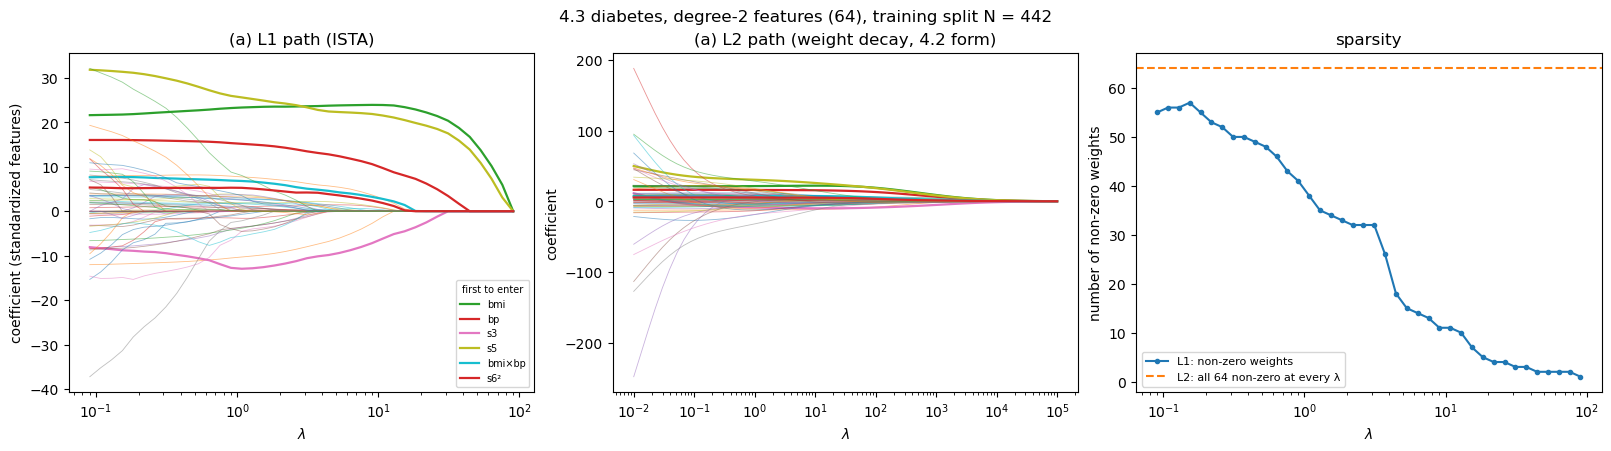

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
for j in range(64):
    hl = j in first
    kw = dict(lw=1.6 if hl else 0.6, alpha=1 if hl else 0.5, label=names_d[j] if hl else None)
    axes[0].semilogx(LAM1, W1[:, 1 + j], **kw)
    axes[1].semilogx(LAM2, W2[:, 1 + j], **kw)
axes[0].set(xlabel=r"$\lambda$", ylabel="coefficient (standardized features)", title=r"(a) L1 path (ISTA)")
axes[1].set(xlabel=r"$\lambda$", ylabel="coefficient", title=r"(a) L2 path (weight decay, 4.2 form)")
axes[0].legend(fontsize=7, title="first to enter", title_fontsize=7)
axes[2].semilogx(LAM1, nnz1, "o-", ms=3, label="L1: non-zero weights")
axes[2].axhline(64, color="C1", ls="--", label="L2: all 64 non-zero at every λ")
axes[2].set(xlabel=r"$\lambda$", ylabel="number of non-zero weights", title="sparsity")
axes[2].legend(fontsize=8)
fig.suptitle(f"4.3 diabetes, degree-2 features (64), training split N = {N3}")
mc.savefig(fig, "4_3a_paths")
plt.show()

**Interpretation.** The L1 path adds weights one at a time (1 non-zero at $\lambda_{max}=90.3$, 7 at $0.17\lambda_{max}$, 55 at $0.001\lambda_{max}$), starting with bmi, s5 and bp, while L2 keeps all 64 weights non-zero at every $\lambda$. Weight decay shrinks coefficients but never selects features. ISTA needs a median of 1726 iterations per $\lambda$ and reaches the 100 000-iteration cap for at least one $\lambda$, because $\kappa(Z)=5470$ and its step is set by the largest curvature.

### 4.3(b) Why L1 gives exact zeros and L2 does not

- **Geometry.** Weight decay and the lasso minimize $E_{in}$ subject to $\lVert w\rVert_2\le C$ or $\lVert w\rVert_1\le C$. The $L_2$ ball is round, so the first contact with an elliptical $E_{in}$ contour is generically at a point where every coordinate is non-zero. The $L_1$ ball is a cross-polytope with corners and edges *on the axes*, and for a generic contour the first contact happens at a corner or edge, where some coordinates are exactly zero. The smaller $C$ (larger $\lambda$), the more likely a low-dimensional face.
- **Optimality (subgradient).** $w_j=0$ is optimal for the lasso iff $|\partial E_{in}/\partial w_j|\le\lambda$: a whole interval of gradients is absorbed at zero. For weight decay, $\partial/\partial w_j\,[E_{in}+\lambda w^Tw/N]=0$ has a single solution, generically $\neq0$.
- **Algorithm.** ISTA's prox step $S_{\eta\lambda}$ maps every $|v_j|\le\eta\lambda$ to exactly 0. Weight decay's closed form only *scales* each singular direction by $s_i^2/(s_i^2+\lambda)>0$, which is never exactly 0.

In [14]:
# Library comparison: Lasso and Ridge
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, Ridge

# Lasso: lambda = 2 alpha
# Ridge: alpha = lambda
lasso_ref = {}
match = []
for frac in (0.1, 0.01, 0.001):
    lam = frac * lam_max
    w_o, h = mc.prox_gradient(lg3, np.zeros(X3.shape[1]), eta3, lam, 300_000, tol=1e-12)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        sk = Lasso(alpha=lam / 2, tol=1e-12, max_iter=10**6).fit(Z3, y3)
    w_sk = np.r_[sk.intercept_, sk.coef_]
    lasso_ref[frac] = (lam, w_o, w_sk)
    match.append(np.max(np.abs(w_o - w_sk)))
    print(f"Lasso  lambda = {lam:8.4f} (alpha = {lam / 2:.4f}): max|w_ours - w_sklearn| = {match[-1]:.1e}  "
          f"[ISTA {h.size - 1} iterations, {np.sum(w_o[1:] != 0)} non-zero{', sklearn ConvergenceWarning' if caught else ''}]")
for lam in (1.0, 10.0, 100.0):
    w_o = mc.ridge_svd(X3, y3, lam)["W"][0]
    r = Ridge(alpha=lam, tol=1e-12).fit(Z3, y3)
    match.append(np.max(np.abs(w_o - np.r_[r.intercept_, r.coef_])))
    print(f"Ridge  lambda = alpha = {lam:6.1f}: max|w_ours - w_sklearn| = {match[-1]:.1e}")
assert max(match) <= 1e-4

Lasso  lambda =   9.0320 (alpha = 4.5160): max|w_ours - w_sklearn| = 1.6e-11  [ISTA 875 iterations, 11 non-zero]
Lasso  lambda =   0.9032 (alpha = 0.4516): max|w_ours - w_sklearn| = 3.3e-10  [ISTA 13737 iterations, 41 non-zero]


Lasso  lambda =   0.0903 (alpha = 0.0452): max|w_ours - w_sklearn| = 4.2e-09  [ISTA 129538 iterations, 55 non-zero]
Ridge  lambda = alpha =    1.0: max|w_ours - w_sklearn| = 3.1e-12
Ridge  lambda = alpha =   10.0: max|w_ours - w_sklearn| = 4.8e-13
Ridge  lambda = alpha =  100.0: max|w_ours - w_sklearn| = 7.0e-14


**Interpretation.** With $\lambda=2\alpha$ for `Lasso` (scikit-learn halves the squared error) and $\alpha=\lambda$ for `Ridge` (the $1/N$ factors cancel), our ISTA and ridge solutions match scikit-learn to $\le4.2\times10^{-9}$ and $\le3.1\times10^{-12}$, far inside the required $10^{-4}$. The remaining gap is the solvers' stopping tolerance.

## 4.4 Regularized logistic regression

Breast cancer, degree-2 polynomial features ($30+30+435=495$), trained on a deliberately small random subset of $N_{train}=100$ and tested on the remaining 469. Malignant (target 0) is $+1$.
- **L2:** $E_{in}+\lambda\lVert\tilde w\rVert^2$, solved by L-BFGS warm-started along the $\lambda$ path.
- **L1:** $E_{in}+\lambda\lVert\tilde w\rVert_1$, solved by proximal gradient (`mc.prox_path`).

With 495 features and 100 points the training set is linearly separable, so $\lambda=0$ has no finite minimizer (cf. 3.4). It is shown as an L-BFGS run (cap 1000 iterations), which stops wherever its tolerance fires on the way to $\lVert w\rVert\to\infty$ (DECISIONS row 19).
$\lambda$ is chosen by 5-fold CV on the 100 training points only, with standardization refitted inside each fold. The test set is used for reporting only (DECISIONS rows 5, 19).

In [15]:
bc = load_breast_cancer()
yb = np.where(bc.target == 0, 1.0, -1.0)
Pb, combos_b = mc.poly_features(bc.data, 2), mc.poly_feature_combos(30, 2)
names_b = [term_name(c, bc.feature_names) for c in combos_b]
idx = mc.rng_for("4_4_subset").permutation(yb.size)
tr4, te4 = idx[:100], idx[100:]
Z4, prm4 = mc.standardize(Pb[tr4])
X4, y4 = mc.add_bias(Z4), yb[tr4]
X4te, y4te = mc.add_bias(mc.apply_standardize(Pb[te4], prm4)), yb[te4]
m4 = X4.shape[1]
print(f"{Pb.shape[1]} features; train {tr4.size} ({np.sum(y4 == 1)} malignant), test {te4.size} ({np.sum(y4te == 1)} malignant)")


def l2_path(Xtr, ytr, lams):
    W, w = [], np.zeros(Xtr.shape[1])
    for lam in lams:
        w, _ = mc.lbfgs(lambda v: mc.logistic_loss_grad(v, Xtr, ytr, lam), w)
        W.append(w)
    return np.array(W)


def l1_path(Xtr, ytr, lams):
    lg = lambda v: mc.logistic_loss_grad(v, Xtr, ytr)  # noqa: E731
    return mc.prox_path(lg, Xtr.shape[1], 1 / mc.lipschitz_logistic(Xtr), lams, 20_000, tol=1e-6)[0]


def err01(W, X, y):
    return np.mean(np.where(X @ W.T > 0, 1, -1) != y[:, None], axis=0)


p = np.mean(y4 == 1)
w_bias = np.r_[np.log(p / (1 - p)), np.zeros(m4 - 1)]                 # bias-only optimum
lam1_max = np.max(np.abs(mc.logistic_loss_grad(w_bias, X4, y4)[1][1:]))
LAM_L2 = np.logspace(1, -4, 26)                                       # decreasing: warm starts
LAM_L1 = lam1_max * np.logspace(0, -3, 26)
t0 = time.perf_counter()
W_l2, W_l1 = l2_path(X4, y4, LAM_L2), l1_path(X4, y4, LAM_L1)
w0, res0 = mc.lbfgs(lambda v: mc.logistic_loss_grad(v, X4, y4), np.zeros(m4), maxiter=1000)
print(f"paths fitted in {time.perf_counter() - t0:.1f} s; lambda_max for L1 = {lam1_max:.3f}")
print(f"lambda = 0 (no finite minimizer; cap 1000): L-BFGS stopped after {res0.nit} iterations (success flag = {res0.success}, message: {res0.message}), ||w|| = {np.linalg.norm(w0):.1f}, "
      f"Ein = {res0.fun:.2e}, train error {mc.ein_01(w0, X4, y4):.3f}, test error {mc.ein_01(w0, X4te, y4te):.3f}")
err = {"L2": (err01(W_l2, X4, y4), err01(W_l2, X4te, y4te)), "L1": (err01(W_l1, X4, y4), err01(W_l1, X4te, y4te))}
nnz_l1 = np.sum(W_l1[:, 1:] != 0, axis=1)


def logistic_fp(path_fn, lams):
    def fp(P_tr, y_tr, P_val):
        Z_tr, prm = mc.standardize(P_tr)                              # refitted inside each fold
        return path_fn(mc.add_bias(Z_tr), y_tr, lams) @ mc.add_bias(mc.apply_standardize(P_val, prm)).T
    return fp


t0 = time.perf_counter()
folds4 = mc.kfold_indices(100, 5, mc.rng_for("4_4_cv"))
cv = {"L2": mc.cv_curve(logistic_fp(l2_path, LAM_L2), Pb[tr4], y4, folds4, loss="01")[0],
      "L1": mc.cv_curve(logistic_fp(l1_path, LAM_L1), Pb[tr4], y4, folds4, loss="01")[0]}
best = {k: int(np.argmin(v)) for k, v in cv.items()}                 # ties go to the larger lambda
print(f"5-fold CV in {time.perf_counter() - t0:.1f} s")
for k, lams in (("L2", LAM_L2), ("L1", LAM_L1)):
    b = best[k]
    tr_e, te_e = err[k]
    extra = f", {nnz_l1[b]} of 495 features survive" if k == "L1" else ""
    print(f"{k}: lambda* = {lams[b]:.3g} (CV error {cv[k][b]:.3f}) -> train error {tr_e[b]:.3f}, test error {te_e[b]:.3f} "
          f"(best test error over the grid {te_e.min():.3f}, not used for selection){extra}")
    print(f"     test error at the largest / smallest lambda: {te_e[0]:.3f} / {te_e[-1]:.3f}")

495 features; train 100 (33 malignant), test 469 (179 malignant)


paths fitted in 14.1 s; lambda_max for L1 = 0.383
lambda = 0 (no finite minimizer; cap 1000): L-BFGS stopped after 42 iterations (success flag = True, message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL), ||w|| = 15.9, Ein = 1.20e-12, train error 0.000, test error 0.062


5-fold CV in 66.3 s
L2: lambda* = 0.631 (CV error 0.030) -> train error 0.030, test error 0.049 (best test error over the grid 0.036, not used for selection)
     test error at the largest / smallest lambda: 0.126 / 0.058
L1: lambda* = 0.0183 (CV error 0.040) -> train error 0.010, test error 0.041 (best test error over the grid 0.041, not used for selection), 18 of 495 features survive
     test error at the largest / smallest lambda: 0.382 / 0.064


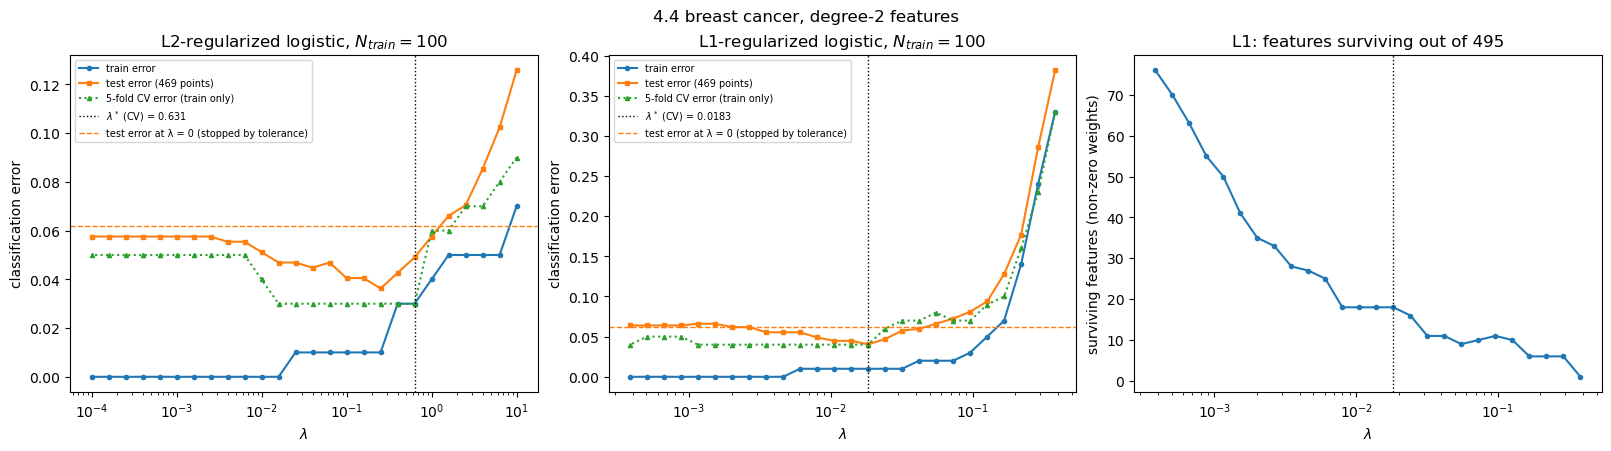

features surviving at lambda* = 0.0183 (sorted by |w|; positive = pushes towards malignant):
  +1.394  worst smoothness×worst concave points
  +0.702  mean smoothness×radius error
  +0.580  mean texture×mean area
  +0.517  mean texture×worst radius
  +0.471  mean area×worst texture
  +0.361  mean texture×radius error
  +0.227  mean radius×worst texture
  -0.172  fractal dimension error²
  +0.167  radius error×texture error
  +0.101  mean radius×mean texture
  +0.090  worst concave points²
  +0.073  radius error×worst texture
  +0.073  radius error
  +0.070  worst texture×worst concave points
  +0.062  mean area×worst smoothness
  +0.031  smoothness error×worst area
  +0.014  worst radius×worst texture
  +0.002  mean radius×worst smoothness


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
for ax, (k, lams) in zip(axes[:2], (("L2", LAM_L2), ("L1", LAM_L1))):
    tr_e, te_e = err[k]
    ax.semilogx(lams, tr_e, "o-", ms=3, label="train error")
    ax.semilogx(lams, te_e, "s-", ms=3, label=f"test error ({te4.size} points)")
    ax.semilogx(lams, cv[k], "^:", ms=3, label="5-fold CV error (train only)")
    ax.axvline(lams[best[k]], color="k", ls=":", lw=1, label=rf"$\lambda^*$ (CV) = {lams[best[k]]:.3g}")
    ax.axhline(mc.ein_01(w0, X4te, y4te), color="C1", ls="--", lw=1, label="test error at λ = 0 (stopped by tolerance)")
    ax.set(xlabel=r"$\lambda$", ylabel="classification error", title=f"{k}-regularized logistic, $N_{{train}} = 100$")
    ax.legend(fontsize=7)
axes[2].semilogx(LAM_L1, nnz_l1, "o-", ms=3)
axes[2].axvline(LAM_L1[best["L1"]], color="k", ls=":", lw=1)
axes[2].set(xlabel=r"$\lambda$", ylabel="surviving features (non-zero weights)", title="L1: features surviving out of 495")
fig.suptitle("4.4 breast cancer, degree-2 features")
mc.savefig(fig, "4_4_logistic")
plt.show()

b = best["L1"]
surv = np.flatnonzero(W_l1[b, 1:])
print(f"features surviving at lambda* = {LAM_L1[b]:.3g} (sorted by |w|; positive = pushes towards malignant):")
for j in surv[np.argsort(-np.abs(W_l1[b, 1 + surv]))]:
    print(f"  {W_l1[b, 1 + j]:+.3f}  {names_b[j]}")

**Interpretation.** With 495 features and 100 points the data are separable, so $\lambda=0$ stops at an arbitrary point (test error 0.062). 5-fold CV picks $\lambda^*=0.631$ for L2 (test error 0.049) and $\lambda^*=0.0183$ for L1 (0.041), which keeps 18 of 495 features. The survivors combine smoothness, concave points, texture, radius and area, the size and shape irregularities of malignant nuclei, so they make clinical sense.

## 4.5 ⋆ Validation and cross-validation

**4.5(a) closed-form LOOCV for weight decay** (derivation in the report, via Sherman–Morrison):
$$E_{cv}(\lambda)=\frac1N\sum_{n=1}^N\left(\frac{\hat y_n-y_n}{1-H_{nn}(\lambda)}\right)^2,\qquad H(\lambda)=Z(Z^TZ+\lambda P)^{-1}Z^T .$$
It holds for any fixed penalty matrix $P$, including our unpenalized bias $P=\mathrm{diag}(0,1,\dots,1)$, because $\lambda$ does not change when a point is left out.
Brute force refits on $N-1$ points with the same $\lambda$. Validation, K-fold and LOO all use `mc.cv_curve`; LOO in closed form uses `mc.loocv_ridge`.

penalize_bias=False: max |closed form - brute force| over 62 lambdas = 6.01e-13
penalize_bias=True : max |closed form - brute force| over 62 lambdas = 1.34e-12
N =    50: closed form     0.07 ms | brute force       3.2 ms | ratio     46x
N =   100: closed form     0.08 ms | brute force       6.9 ms | ratio     86x
N =   200: closed form     0.11 ms | brute force      16.4 ms | ratio    145x


N =   400: closed form     0.16 ms | brute force      44.5 ms | ratio    278x


N =   800: closed form     0.28 ms | brute force     138.9 ms | ratio    494x


N =  1600: closed form     0.55 ms | brute force     533.0 ms | ratio    964x
log-log slopes, all N: closed form 0.60, brute force 1.47; N >= 200: closed form 0.77, brute force 1.67 (median of 5 repeats, 62 lambdas each)


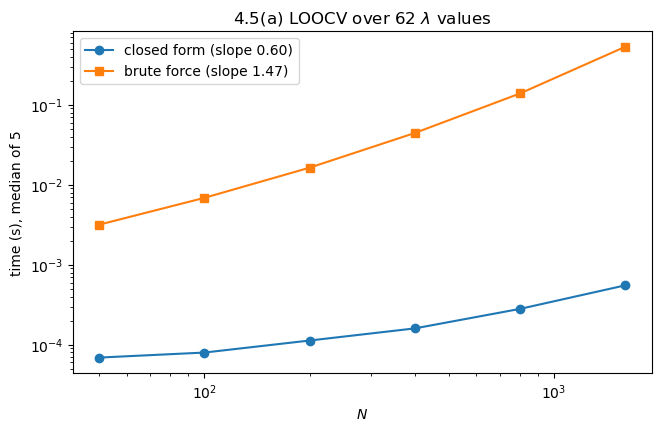

In [17]:
r = mc.rng_for("4_5a")
x, y, a = mc.legendre_dataset(r, 40, 0.5, 15)
Z = mc.legendre_features(x, 10)
for pb in (False, True):
    closed = mc.loocv_ridge(Z, y, LAMS, pb)
    brute = mc.cv_curve(mc.ridge_fit_predict(LAMS, pb), Z, y, mc.kfold_indices(40, 40, r))[0]
    diff = np.max(np.abs(closed - brute))
    print(f"penalize_bias={pb!s:<5}: max |closed form - brute force| over {LAMS.size} lambdas = {diff:.2e}")
    assert diff < 1e-10


def median_time(fn, repeats=5):
    fn()                                    # warm-up, not timed
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


N_time = [50, 100, 200, 400, 800, 1600]
t_closed, t_brute = [], []
for N in N_time:
    x, y, _ = mc.legendre_dataset(r, N, 0.5, 15)        # data generation is outside the timed region
    Z = mc.legendre_features(x, 10)
    folds = mc.kfold_indices(N, N, r)
    t_closed.append(median_time(lambda: mc.loocv_ridge(Z, y, LAMS)))
    t_brute.append(median_time(lambda: mc.cv_curve(mc.ridge_fit_predict(LAMS), Z, y, folds)))
    print(f"N = {N:5d}: closed form {t_closed[-1] * 1e3:8.2f} ms | brute force {t_brute[-1] * 1e3:9.1f} ms | ratio {t_brute[-1] / t_closed[-1]:6.0f}x")
slope_c = np.polyfit(np.log(N_time), np.log(t_closed), 1)[0]
slope_b = np.polyfit(np.log(N_time), np.log(t_brute), 1)[0]
big = slice(2, None)   # N >= 200
slope_c_big = np.polyfit(np.log(N_time[big]), np.log(t_closed[big]), 1)[0]
slope_b_big = np.polyfit(np.log(N_time[big]), np.log(t_brute[big]), 1)[0]
print(f"log-log slopes, all N: closed form {slope_c:.2f}, brute force {slope_b:.2f}; "
      f"N >= 200: closed form {slope_c_big:.2f}, brute force {slope_b_big:.2f} (median of 5 repeats, {LAMS.size} lambdas each)")

fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
ax.loglog(N_time, t_closed, "o-", label=f"closed form (slope {slope_c:.2f})")
ax.loglog(N_time, t_brute, "s-", label=f"brute force (slope {slope_b:.2f})")
ax.set(xlabel="$N$", ylabel="time (s), median of 5", title=rf"4.5(a) LOOCV over {LAMS.size} $\lambda$ values")
ax.legend()
mc.savefig(fig, "4_5a_loocv_timing")
plt.show()

**Interpretation.** The closed form matches brute-force LOO to $6.0\times10^{-13}$ (unpenalized bias) and $1.3\times10^{-12}$ (penalized). It needs one SVD instead of $N$ fits, so at $N=1600$ it is about three orders of magnitude faster, with log-log slopes near 0.8 against 1.7 for $N\ge200$.

In [18]:
RUNS_SEL, N_SEL, S2_SEL = 500, 40, 0.5
K_VAL = [5, 10, 15, 20, 25]
METHODS = [f"val K={K}" for K in K_VAL] + ["5-fold", "10-fold", "LOOCV"]
rng = mc.rng_for("4_5b")
fp = mc.ridge_fit_predict(LAMS)
res = {m: {"eout": [], "eout_reduced": [], "eval": [], "lam": []} for m in METHODS}
oracle = []
for run in range(RUNS_SEL):
    x, y, a = mc.legendre_dataset(rng, N_SEL, S2_SEL, 15)
    Z = mc.legendre_features(x, 10)
    eout_all = mc.eout_legendre(mc.ridge_svd(Z, y, LAMS)["W"], a, S2_SEL)   # every lambda, trained on all N
    oracle.append(eout_all.min())
    for K in K_VAL:
        tr, va = mc.random_split(N_SEL, K / N_SEL, rng)
        assert va.size == K
        e_val = mc.cv_curve(fp, Z, y, [(tr, va)])[0]
        k = int(np.argmin(e_val))
        w_reduced = mc.ridge_svd(Z[tr], y[tr], LAMS[k])["W"][0]
        d = res[f"val K={K}"]
        d["eout"].append(eout_all[k])                                      # retrained on all N (DECISIONS row 6)
        d["eout_reduced"].append(mc.eout_legendre(w_reduced, a, S2_SEL))   # the model Eval was measured on
        d["eval"].append(e_val[k])
        d["lam"].append(LAMS[k])
    for K in (5, 10):
        e_cv = mc.cv_curve(fp, Z, y, mc.kfold_indices(N_SEL, K, rng))[0]
        k = int(np.argmin(e_cv))
        d = res[f"{K}-fold"]
        d["eout"].append(eout_all[k]); d["eval"].append(e_cv[k]); d["lam"].append(LAMS[k])
    e_loo = mc.loocv_ridge(Z, y, LAMS)
    k = int(np.argmin(e_loo))
    d = res["LOOCV"]
    d["eout"].append(eout_all[k]); d["eval"].append(e_loo[k]); d["lam"].append(LAMS[k])

oracle = np.array(oracle)
res = {m: {key: np.array(v) for key, v in d.items()} for m, d in res.items()}
om, ose = mc.mean_se(oracle)
print(f"N = {N_SEL}, Qf = 15, sigma^2 = {S2_SEL}, H10, {RUNS_SEL} runs; oracle Eout(lambda*) = {om:.4f} ± {ose:.4f}")
print(f"oracle median = {np.median(oracle):.4f}")
print(f"{'method':<10}{'Eout retrained':>20}{'Eout reduced':>20}{'regret (retrained)':>22}{'selected Eval':>20}"
      f"{'median Eout':>13}{'median lambda':>15}{'lambda<=1e-2':>14}{'Eout>2x oracle':>16}")
for m in METHODS:
    d = res[m]
    e, ese = mc.mean_se(d["eout"])
    g, gse = mc.mean_se(d["eout"] - oracle)
    v, vse = mc.mean_se(d["eval"])
    red = "{:.4f} ± {:.4f}".format(*mc.mean_se(d["eout_reduced"])) if d["eout_reduced"].size else "-"
    print(f"{m:<10}{e:>12.4f} ± {ese:.4f}{red:>20}{g:>14.4f} ± {gse:.4f}{v:>12.4f} ± {vse:.4f}"
          f"{np.median(d['eout']):>13.4f}{np.median(d['lam']):>15.3g}{np.mean(d['lam'] <= 1e-2):>14.1%}{np.mean(d['eout'] > 2 * oracle):>16.1%}")

N = 40, Qf = 15, sigma^2 = 0.5, H10, 500 runs; oracle Eout(lambda*) = 0.7778 ± 0.0066
oracle median = 0.7415
method          Eout retrained        Eout reduced    regret (retrained)       selected Eval  median Eout  median lambda  lambda<=1e-2  Eout>2x oracle
val K=5        13.0813 ± 5.2357     7.2393 ± 2.6817       12.3035 ± 5.2356      0.6430 ± 0.0337       0.8800              1         21.0%           10.8%
val K=10       13.5433 ± 5.6961     8.8517 ± 3.8724       12.7654 ± 5.6959      0.7074 ± 0.0219       0.8479          0.897         15.4%           10.2%
val K=15        3.0834 ± 0.9619     2.3756 ± 0.5507        2.3056 ± 0.9617      0.7803 ± 0.0184       0.8342           1.26          9.0%            5.6%
val K=20        1.0923 ± 0.0779     1.0466 ± 0.0402        0.3144 ± 0.0767      0.8109 ± 0.0165       0.8261           1.26          7.2%            4.6%
val K=25        0.9182 ± 0.0235     1.0176 ± 0.0132        0.1404 ± 0.0217      0.8868 ± 0.0168       0.8179              1 

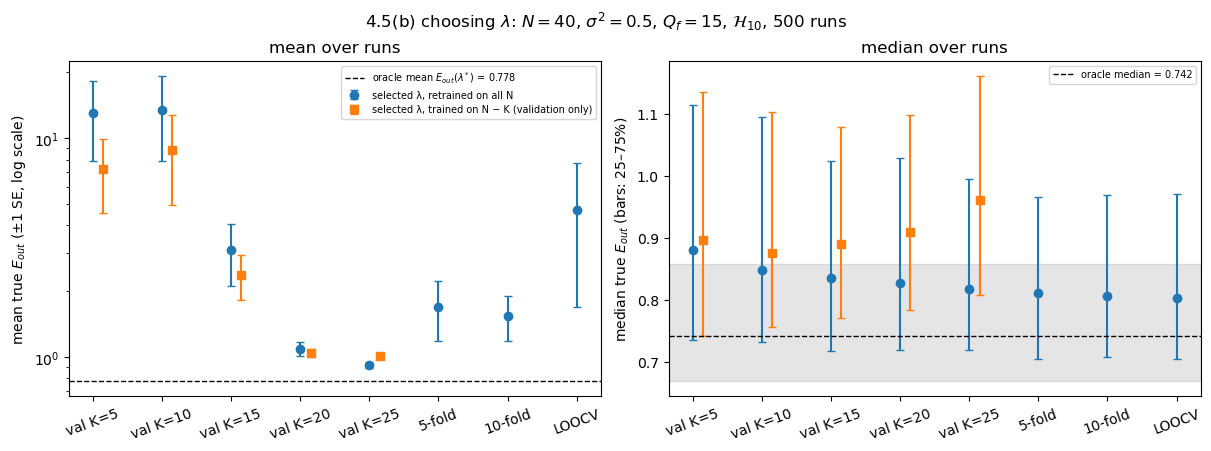

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
xs = np.arange(len(METHODS))
val_idx = [i for i, m in enumerate(METHODS) if m.startswith("val")]
# left: mean ± SE; right: median and 25-75% range
ax = axes[0]
m_ret = [mc.mean_se(res[m]["eout"]) for m in METHODS]
ax.errorbar(xs, [v[0] for v in m_ret], yerr=[v[1] for v in m_ret], fmt="o", capsize=3, label="selected λ, retrained on all N")
m_red = [mc.mean_se(res[METHODS[i]]["eout_reduced"]) for i in val_idx]
ax.errorbar(np.array(val_idx) + 0.15, [v[0] for v in m_red], yerr=[v[1] for v in m_red], fmt="s", capsize=3,
            label="selected λ, trained on N − K (validation only)")
ax.axhline(om, color="k", ls="--", lw=1, label=rf"oracle mean $E_{{out}}(\lambda^*)$ = {om:.3f}")
ax.set(yscale="log", ylabel=r"mean true $E_{out}$ (±1 SE, log scale)", title="mean over runs")
ax.legend(fontsize=7)
ax = axes[1]
for i, m in enumerate(METHODS):
    q25, q50, q75 = np.percentile(res[m]["eout"], [25, 50, 75])
    ax.errorbar(i, q50, yerr=[[q50 - q25], [q75 - q50]], fmt="o", color="C0", capsize=3)
    if m.startswith("val"):
        q25, q50, q75 = np.percentile(res[m]["eout_reduced"], [25, 50, 75])
        ax.errorbar(i + 0.15, q50, yerr=[[q50 - q25], [q75 - q50]], fmt="s", color="C1", capsize=3)
q25, q50, q75 = np.percentile(oracle, [25, 50, 75])
ax.axhline(q50, color="k", ls="--", lw=1, label=f"oracle median = {q50:.3f}")
ax.axhspan(q25, q75, color="k", alpha=0.1)
ax.set(ylabel=r"median true $E_{out}$ (bars: 25–75%)", title="median over runs")
ax.legend(fontsize=7)
for ax in axes:
    ax.set_xticks(xs, METHODS, rotation=20)
fig.suptitle(rf"4.5(b) choosing $\lambda$: $N = {N_SEL}$, $\sigma^2 = {S2_SEL}$, $Q_f = 15$, $\mathcal{{H}}_{{10}}$, {RUNS_SEL} runs")
mc.savefig(fig, "4_5b_selection")
plt.show()

**Interpretation.** In the typical run K-fold CV and LOO come closest to the oracle (medians 0.80 to 0.81 against 0.74), and a small validation set does worst (0.880 for $K=5$). The means are dominated by rare runs that pick a tiny $\lambda$: $K=5$ ends above twice the oracle in 10.8% of runs and 10-fold CV in 5.0%. $K=25$ has the lowest mean ($0.918\pm0.024$) because a large validation set rarely mistakes a wild model for a good one.

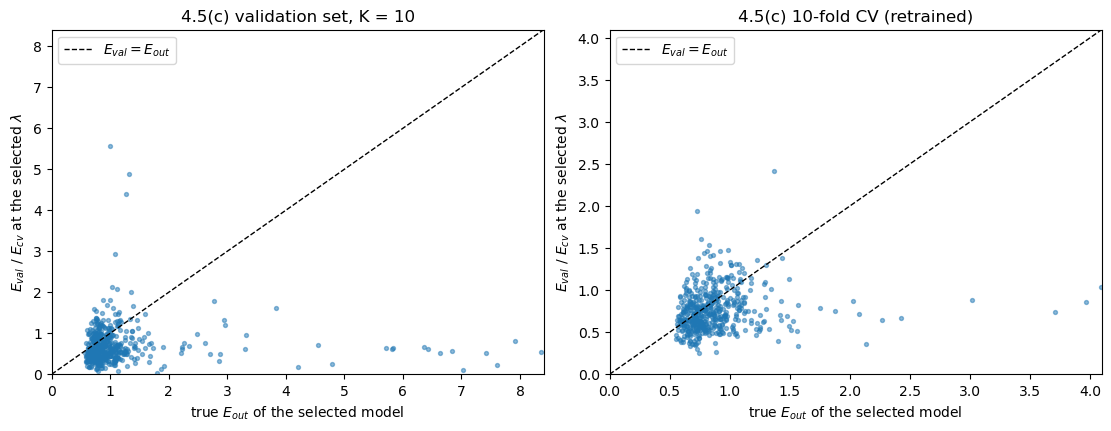

mean (selected validation error - true Eout), 500 runs:
  val K=5     -6.5963 ± 2.6819   median -0.4598   (fraction of runs optimistic: 81%)
  val K=10    -8.1443 ± 3.8731   median -0.2999   (fraction of runs optimistic: 77%)
  val K=15    -1.5953 ± 0.5519   median -0.2260   (fraction of runs optimistic: 71%)
  val K=20    -0.2357 ± 0.0422   median -0.1574   (fraction of runs optimistic: 71%)
  val K=25    -0.1308 ± 0.0168   median -0.1544   (fraction of runs optimistic: 65%)
  5-fold      -0.9211 ± 0.5170   median -0.0729   (fraction of runs optimistic: 64%)
  10-fold     -0.7813 ± 0.3581   median -0.0991   (fraction of runs optimistic: 65%)
  LOOCV       -3.9336 ± 3.0038   median -0.1082   (fraction of runs optimistic: 66%)


In [20]:
pairs = [("val K=10", "eout_reduced", "validation set, K = 10"), ("10-fold", "eout", "10-fold CV (retrained)")]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, (m, key, title) in zip(axes, pairs):
    ev, eo = res[m]["eval"], res[m][key]
    hi = np.percentile(np.r_[ev, eo], 99)
    ax.scatter(eo, ev, s=8, alpha=0.5)
    ax.plot([0, hi], [0, hi], "k--", lw=1, label="$E_{val} = E_{out}$")
    ax.set(xlim=(0, hi), ylim=(0, hi), xlabel=r"true $E_{out}$ of the selected model",
           ylabel=r"$E_{val}$ / $E_{cv}$ at the selected $\lambda$", title=f"4.5(c) {title}")
    ax.legend()
mc.savefig(fig, "4_5c_optimism")
plt.show()

print("mean (selected validation error - true Eout), 500 runs:")
for m in METHODS:
    key = "eout_reduced" if m.startswith("val") else "eout"
    diff = res[m]["eval"] - res[m][key]
    g, gse = mc.mean_se(diff)
    print(f"  {m:<10}{g:>9.4f} ± {gse:.4f}   median {np.median(diff):7.4f}   (fraction of runs optimistic: {np.mean(diff < 0):.0%})")

**Interpretation.** The selected model's validation error is optimistic in 65% to 81% of runs (median gap $-0.46$ for $K=5$ to $-0.07$ for 5-fold CV). Each $E_{val}(\lambda)$ is unbiased, but we report the minimum of 62 noisy estimates, which is biased low, so a validation set used for selection no longer estimates $E_{out}$.

## 4.6 ⋆ Data snooping

Pure noise: $N=50$ points, 1000 independent $N(0,1)$ features, labels $\pm1$ by fair coin, so **every classifier has $E_{out}=0.5$**. 100 repetitions.
- **(a)** Select the 20 features most correlated with the labels **using all 50 points**, then estimate the error of logistic regression by 10-fold CV.
- **(b)** The same folds, but the 20 features are selected **inside each fold**, from its 45 training points only.

Training folds of 45 points with 20 features can be separable, so a tiny L2 penalty $\lambda=10^{-3}$ keeps every fit finite (DECISIONS row 19).
Reference: Hastie, Tibshirani, Friedman, *ESL* §7.10.2.

100 repetitions in 1.6 s (true Eout = 0.5 for every classifier)
(a) select on all data, then CV:   CV error 0.103 ± 0.006   (min 0.00, max 0.28, below 0.3 in 100% of repetitions)
(b) select inside each fold:       CV error 0.508 ± 0.010   (min 0.30, max 0.76)
mean |corr| of the 20 selected noise features in (a): 0.370  vs  typical |corr| of a single noise feature ~ 1/sqrt(N) = 0.141


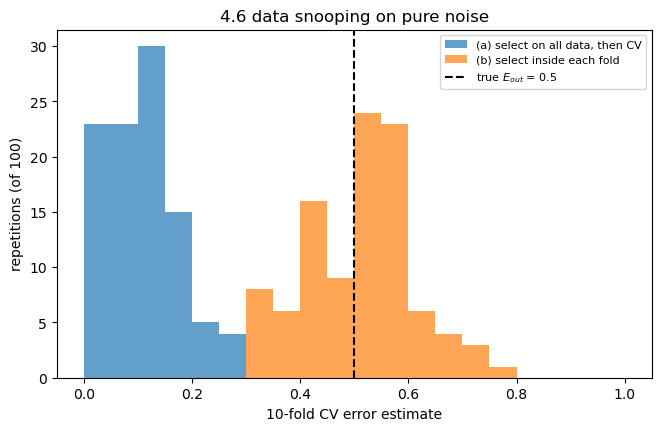

In [21]:
REPS6, N6, P6, K6, KF6, LAM6 = 100, 50, 1000, 20, 10, 1e-3
rng6 = mc.rng_for("4_6")


def top_k(X, y, k):
    Xc, yc = X - X.mean(axis=0), y - y.mean()
    corr = (Xc.T @ yc) / (np.linalg.norm(Xc, axis=0) * np.linalg.norm(yc))
    sel = np.argsort(-np.abs(corr))[:k]
    return sel, np.abs(corr[sel])


def cv_error(X, y, folds, cols_all=None):
    errs = []
    for tr, va in folds:
        cols = cols_all if cols_all is not None else top_k(X[tr], y[tr], K6)[0]   # (b): selection on the training fold only
        Xtr = mc.add_bias(X[tr][:, cols])
        w, _ = mc.lbfgs(lambda v: mc.logistic_loss_grad(v, Xtr, y[tr], LAM6), np.zeros(K6 + 1))
        errs.append(mc.error_rate(y[va], mc.predict_sign(w, mc.add_bias(X[va][:, cols]))))
    return np.mean(errs)


t0 = time.perf_counter()
cv_a, cv_b, corr_a = np.zeros(REPS6), np.zeros(REPS6), np.zeros(REPS6)
for r in range(REPS6):
    X6 = rng6.standard_normal((N6, P6))
    y6 = np.where(rng6.random(N6) < 0.5, 1.0, -1.0)
    sel, c = top_k(X6, y6, K6)                                    # (a): selection on ALL the data
    folds = mc.kfold_indices(N6, KF6, rng6)
    cv_a[r], cv_b[r], corr_a[r] = cv_error(X6, y6, folds, sel), cv_error(X6, y6, folds), c.mean()
print(f"{REPS6} repetitions in {time.perf_counter() - t0:.1f} s (true Eout = 0.5 for every classifier)")
print("(a) select on all data, then CV:   CV error {:.3f} ± {:.3f}".format(*mc.mean_se(cv_a)) + f"   (min {cv_a.min():.2f}, max {cv_a.max():.2f}, below 0.3 in {np.mean(cv_a < 0.3):.0%} of repetitions)")
print("(b) select inside each fold:       CV error {:.3f} ± {:.3f}".format(*mc.mean_se(cv_b)) + f"   (min {cv_b.min():.2f}, max {cv_b.max():.2f})")
print(f"mean |corr| of the 20 selected noise features in (a): {corr_a.mean():.3f}  vs  typical |corr| of a single noise feature ~ 1/sqrt(N) = {1 / np.sqrt(N6):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
bins = np.linspace(0, 1, 21)
ax.hist(cv_a, bins=bins, alpha=0.7, label="(a) select on all data, then CV")
ax.hist(cv_b, bins=bins, alpha=0.7, label="(b) select inside each fold")
ax.axvline(0.5, color="k", ls="--", label="true $E_{out}$ = 0.5")
ax.set(xlabel="10-fold CV error estimate", ylabel=f"repetitions (of {REPS6})", title="4.6 data snooping on pure noise")
ax.legend(fontsize=8)
mc.savefig(fig, "4_6_snooping")
plt.show()

**Interpretation.** Every classifier has $E_{out}=0.5$ here, yet selecting features on all 50 points reports a CV error of $0.103\pm0.006$ (below 0.3 in every repetition), while selecting inside each fold gives $0.508\pm0.010$. The selected noise features correlate 0.37 with the labels against a typical 0.14, because selection saw the validation points. The same leak would have entered 3.5 and 4.4 had standardization been fitted before splitting into folds.